# Exploration des données Open Agenda (Nouvelle-Aquitaine)

**Objectif** : observer les données brutes **sans les modifier**, pour repérer les données manquantes ou incorrectes et décider des règles de nettoyage.

**Consignes** (énoncé, étape 2) :
- « Attention aux **données manquantes ou incorrectes**. »
- « Vérifier la **pertinence des filtres** pour s'assurer que les événements sont bien ciblés. »
- Résultat attendu : « un jeu de données d'événements **propre et structuré, prêt à être indexé** ».

**Données** : photo de référence du 29/10/2026 (`data/raw/events_nouvelle-aquitaine_2026-10-29.json.gz`).

**Exécution** : noyau `.venv` (Python 3.12), puis « Run All ». Le nettoyage proprement dit est codé dans `rag/preprocess.py`, avec ses tests.

## 0. Chargement des données

In [1]:
import sys
from pathlib import Path

# Le notebook s'exécute depuis notebooks/ : on ajoute la racine du projet au chemin d'import
# pour pouvoir importer le package rag/ (comme le fait « python -m » depuis la racine).
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json

import matplotlib.pyplot as plt
import pandas as pd

from rag import config
from rag.fetch import load_raw_events

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 30)

In [2]:
RAW_FILE = config.RAW_DATA_DIR / "events_nouvelle-aquitaine_2026-10-29.json.gz"
metadata, events = load_raw_events(RAW_FILE)
df = pd.DataFrame(events)

REFERENCE_DATE = pd.Timestamp(metadata["reference_date"], tz="UTC")
PERIOD_START = REFERENCE_DATE - pd.Timedelta(days=config.HISTORY_DAYS)

print("Filtre utilisé :", metadata["where"])
print("Récupéré le    :", metadata["fetched_at"])
print(f"Taille         : {df.shape[0]} événements x {df.shape[1]} colonnes")

Filtre utilisé : location_region = "Nouvelle-Aquitaine" and lastdate_end >= date'2025-10-29'
Récupéré le    : 2026-10-29T11:56:29+00:00
Taille         : 34517 événements x 26 colonnes


In [3]:
df.dtypes

uid                           str
title_fr                      str
canonicalurl                  str
originagenda_title            str
updatedat                     str
description_fr                str
longdescription_fr            str
keywords_fr                object
firstdate_begin               str
lastdate_end                  str
timings                       str
daterange_fr                  str
location_name                 str
location_address              str
location_city                 str
location_postalcode           str
location_department           str
location_region               str
location_coordinates       object
conditions_fr                 str
age_min                   float64
age_max                   float64
registration                  str
accessibility_label_fr     object
status                        str
attendancemode                str
dtype: object

In [4]:
df.head(3)

,uid,title_fr,canonicalurl,originagenda_title,updatedat,description_fr,longdescription_fr,keywords_fr,firstdate_begin,lastdate_end,timings,daterange_fr,location_name,location_address,location_city,location_postalcode,location_department,location_region,location_coordinates,conditions_fr,age_min,age_max,registration,accessibility_label_fr,status,attendancemode
0,48041281,Le QUIZ de La Ruelle,https://openagenda.com/la-ruelle-segur/events/le-quiz-de-la-ruelle,La Ruelle Segur,2025-11-12T10:39:39+00:00,"Préparez vos neurones, affûtez votre esprit d’équipe et surtout… votre sens ...","<p>Préparez vos neurones, affûtez votre esprit d’équipe et surtout… votre se...",None,2025-11-29T20:00:00+00:00,2025-11-29T22:00:00+00:00,"[{""begin"": ""2025-11-29T21:00:00+01:00"", ""end"": ""2025-11-29T23:00:00+01:00""}]","Samedi 29 novembre, 21h00",La Ruelle,"3 Avenue du Château 19230, SÉGUR-LE-CHÂTEAU",Ségur-le-Château,19230,Corrèze,Nouvelle-Aquitaine,"{'lon': 1.306101, 'lat': 45.428859}",NaN,NaN,NaN,NaN,None,"{""id"": 1, ""label"": {""fr"": ""Programm\u00e9"", ""en"": ""Scheduled"", ""io"": ""crwdns...","{""id"": 1, ""label"": {""fr"": ""Sur place"", ""en"": ""In situ"", ""it"": ""In presenza"",..."
1,44808220,HÔTEL DU PARC - PIRATES,https://openagenda.com/catalogue-structures-accueil-hebergement/events/hotel...,Catalogue départemental des structures d’accueil et d’hébergement - Vienne,2024-03-07T10:37:31+00:00,O,"<p>Hôtel thématisé, adapté aux groupes scolaires, proposant 105 chambres don...",None,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,"[{""begin"": ""2032-01-01T02:00:00+01:00"", ""end"": ""2032-01-01T04:00:00+01:00""}]","Jeudi 1 janvier 2032, 02h00",Hôtel du Parc - Pirates*,Boulevard René Descartes,Chasseneuil-du-Poitou,86360,Vienne,Nouvelle-Aquitaine,"{'lon': 0.358035, 'lat': 46.667828}",NaN,3.0,16.0,"[{""type"": ""phone"", ""value"": ""05 49 49 08 08""}, {""type"": ""link"", ""value"": ""ht...",None,"{""id"": 1, ""label"": {""fr"": ""Programm\u00e9"", ""en"": ""Scheduled"", ""io"": ""crwdns...","{""id"": 1, ""label"": {""fr"": ""Sur place"", ""en"": ""In situ"", ""it"": ""In presenza"",..."
2,55746249,"Pépinière d'Histoires, Stage de création d'histoires autour du végétal",https://openagenda.com/econature/events/pepiniere-dhistoires-stage-de-creati...,EcoNature,2026-04-21T02:01:00+00:00,Créer de nouvelles histoires pour le végétal,"<p>Depuis 2022, Flora &nbsp;(Poétesse-Botaniste) et Philippe &nbsp;(Conteur-...","[Nature, Atelier nature, arbres, biodiversité, plantes sauvages, plantes-com...",2026-05-22T18:00:00+00:00,2026-05-23T18:00:00+00:00,"[{""begin"": ""2026-05-22T20:00:00+02:00"", ""end"": ""2026-05-23T20:00:00+02:00""}]","Vendredi 22 mai, 20h00",Les Minières,Les Minières,La Dornac,24120,Dordogne,Nouvelle-Aquitaine,"{'lon': 1.339228, 'lat': 45.073802}",Tarifs : Tarif réduit 290€ ; Tarif plein 350€,NaN,NaN,"[{""type"": ""link"", ""value"": ""https://www.eco-nature.org/experience/pepiniere-...",None,"{""id"": 1, ""label"": {""fr"": ""Programm\u00e9"", ""en"": ""Scheduled"", ""io"": ""crwdns...","{""id"": 1, ""label"": {""fr"": ""Sur place"", ""en"": ""In situ"", ""it"": ""In presenza"",..."


## 1. Pertinence des filtres

La zone et la période demandées sont-elles bien respectées ? On contrôle la région et les départements, la cohérence des codes postaux, les coordonnées GPS et les dates de fin.

In [5]:
print(df["location_region"].value_counts(dropna=False), "\n")
print(df["location_department"].value_counts(dropna=False))

location_region
Nouvelle-Aquitaine    34517
Name: count, dtype: int64 

location_department
Gironde                 15046
Charente-Maritime        3006
Pyrénées-Atlantiques     2666
Haute-Vienne             2511
Vienne                   2152
Dordogne                 1913
Deux-Sèvres              1526
Charente                 1483
Corrèze                  1285
Landes                   1100
Lot-et-Garonne            917
Creuse                    903
gironde                     8
Pyrénées Orientales         1
Name: count, dtype: int64


In [6]:
# Départements de Nouvelle-Aquitaine : code (2 premiers chiffres du code postal) -> nom (même liste que le
# nettoyage, définie une seule fois dans rag/config.py)
NA_DEPARTMENTS = config.NA_DEPARTMENTS

postal_prefix = df["location_postalcode"].str[:2]
outside_na = ~postal_prefix.isin(list(NA_DEPARTMENTS))
print(f"Codes postaux hors Nouvelle-Aquitaine (ou absents) : {outside_na.sum()}")
missing_code = df["location_postalcode"].fillna("").str.strip() == ""
print(f"  dont code postal absent : {(outside_na & missing_code).sum()} ; d'une autre région : {(outside_na & ~missing_code).sum()}")
print("  Départements déclarés :", df.loc[outside_na, "location_department"].value_counts().head(3).to_dict())
df.loc[outside_na, ["title_fr", "location_city", "location_postalcode", "location_department"]].head(10)

Codes postaux hors Nouvelle-Aquitaine (ou absents) : 217
  dont code postal absent : 197 ; d'une autre région : 20
  Départements déclarés : {'Gironde': 162, 'Haute-Vienne': 19, 'Charente-Maritime': 10}


,title_fr,location_city,location_postalcode,location_department
456,Découverte de la faune et flore de la Réserve Ecologique des Barails,Bordeaux,NaN,Gironde
459,Atelier découpage/collage,Bordeaux,NaN,Gironde
521,Préservons la biodiversité : du Parc Floral à la Réserve Ecologique des Barails,Bordeaux,NaN,Gironde
539,Rencontre avec Eduardo Halfon à la Médiathèque Pierre \nVeilletet à Bordeaux,Bordeaux,NaN,Gironde
540,Projection de Leila et les loups suivie d’une conversation \nentre Touda Bou...,Bordeaux,NaN,Gironde
674,Le drop des commerçants,Bordeaux,NaN,Gironde
1235,Shigeru Ban du minimalisme à l’éclectisme,Limoges,NaN,Haute-Vienne
1496,Visite exploitation La Champignonne (production de champignons dans un block...,Bordeaux,NaN,Gironde
1688,Festival Renc'art à ta porte - 28/04 - Milos Asian,Bordeaux,NaN,Gironde
2566,Visite libre : portes ouvertes de l'Association Pau Pyrénées des Amis du Rai...,Pau,NaN,Pyrénées-Atlantiques


In [7]:
# Le nom du département est-il cohérent avec le code postal ?
expected_department = postal_prefix.map(NA_DEPARTMENTS)
mismatch = expected_department.notna() & (expected_department != df["location_department"])
print(f"Département incohérent avec le code postal : {mismatch.sum()}")
df.loc[mismatch, ["location_city", "location_postalcode", "location_department"]].value_counts().head(10)

Département incohérent avec le code postal : 17


location_city           location_postalcode  location_department
Blanquefort             33290                gironde                8
Segonzac                16130                Charente-Maritime      1
Payzac                  19230                Dordogne               1
Haut-de-Bosdarros       64800                Pyrénées Orientales    1
THIVIERS                24800                Charente               1
ST-YRIEIX-SUR-CHARENTE  16710                Charente-Maritime      1
CHATEAUNEUF/CHARENTE    16120                Haute-Vienne           1
LE PALAIS SUR VIENNE    87410                Dordogne               1
Fougueyrolles           33220                Dordogne               1
Terrasson-Lavilledieu   24120                Corrèze                1
Name: count, dtype: int64

In [8]:
# Coordonnées GPS : présentes, et situées dans la région ?
latitude = pd.to_numeric(df["location_coordinates"].map(lambda c: c.get("lat") if isinstance(c, dict) else None), errors="coerce")
longitude = pd.to_numeric(df["location_coordinates"].map(lambda c: c.get("lon") if isinstance(c, dict) else None), errors="coerce")

# Rectangle englobant approximatif de la Nouvelle-Aquitaine
in_region_box = latitude.between(42.7, 47.2) & longitude.between(-1.9, 2.7)
print(f"Sans coordonnées                 : {latitude.isna().sum()}")
print(f"Hors du rectangle de la région   : {(latitude.notna() & ~in_region_box).sum()}")

Sans coordonnées                 : 0
Hors du rectangle de la région   : 17


In [9]:
# Période : la date de fin doit être postérieure au début de période (date de référence - 1 an)
lastdate_end = pd.to_datetime(df["lastdate_end"], utc=True, errors="coerce")
firstdate_begin = pd.to_datetime(df["firstdate_begin"], utc=True, errors="coerce")

print(f"Début de période                       : {PERIOD_START.date()}")
print(f"Fins antérieures au début de période   : {(lastdate_end < PERIOD_START).sum()}")
print(f"Dates de fin illisibles                : {lastdate_end.isna().sum()}")

Début de période                       : 2025-10-29
Fins antérieures au début de période   : 0
Dates de fin illisibles                : 0


## 2. Données manquantes

Pour chaque champ : quelle part des événements a une valeur renseignée ? Une valeur est considérée comme vide si elle est absente, si c'est un texte vide (ou composé uniquement d'espaces), ou une liste vide.

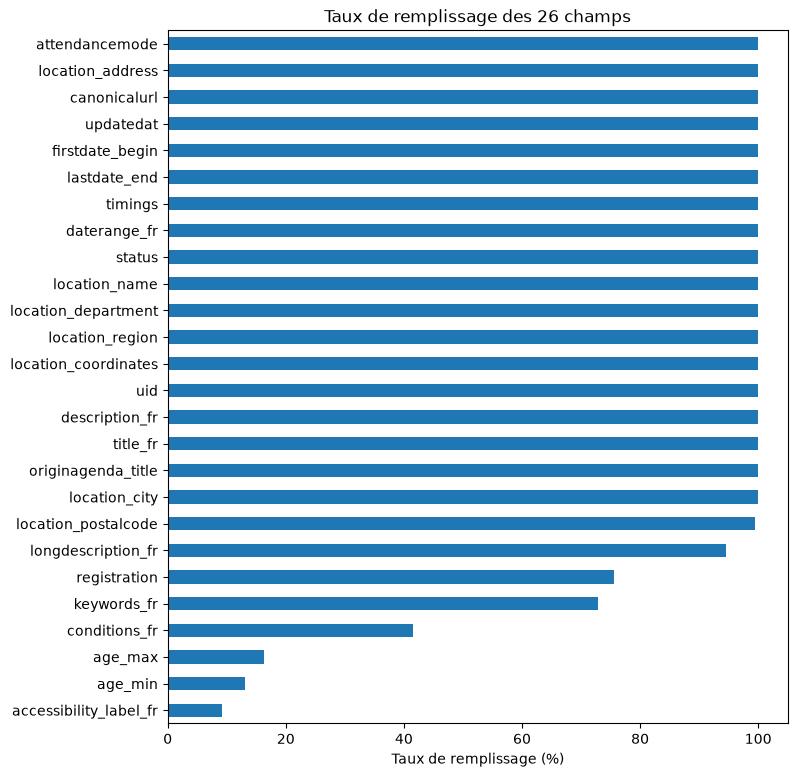

accessibility_label_fr      9.2%
age_min                    13.1%
age_max                    16.3%
conditions_fr              41.6%
keywords_fr                72.8%
registration               75.5%
longdescription_fr         94.6%
location_postalcode        99.4%
location_city              99.9%
originagenda_title        100.0%
title_fr                  100.0%
description_fr            100.0%
uid                       100.0%
location_coordinates      100.0%
location_region           100.0%
location_department       100.0%
location_name             100.0%
status                    100.0%
daterange_fr              100.0%
timings                   100.0%
lastdate_end              100.0%
firstdate_begin           100.0%
updatedat                 100.0%
canonicalurl              100.0%
location_address          100.0%
attendancemode            100.0%
dtype: str

In [10]:
def is_empty(value) -> bool:
    """Vrai si la valeur est absente : None, NaN, texte vide (ou que des espaces), liste ou dict vide."""
    if value is None or value is pd.NA:
        return True
    if isinstance(value, float) and pd.isna(value):
        return True
    if isinstance(value, str):
        return not value.strip()
    if isinstance(value, (list, dict)):
        return len(value) == 0
    return False


fill_rate = df.apply(lambda column: 1 - column.map(is_empty).mean()).sort_values()

ax = (fill_rate * 100).plot.barh(figsize=(8, 9))
ax.set_xlabel("Taux de remplissage (%)")
ax.set_title("Taux de remplissage des 26 champs")
plt.show()

fill_rate.map("{:.1%}".format)

## 3. Données incorrectes

Dates aberrantes, incohérences (début après la fin, âge minimum supérieur à l'âge maximum), statuts et modes de participation.

In [11]:
first_year = pd.to_numeric(df["firstdate_begin"].str[:4], errors="coerce")
last_year = pd.to_numeric(df["lastdate_end"].str[:4], errors="coerce")
print(f"Années de début : de {first_year.min():.0f} à {first_year.max():.0f}")
print(f"Années de fin   : de {last_year.min():.0f} à {last_year.max():.0f}")

aberrant_dates = (first_year < 2000) | (first_year > 2030) | (last_year > 2030)
print(f"Dates aberrantes (avant 2000 ou après 2030) : {aberrant_dates.sum()}")
df.loc[aberrant_dates, ["title_fr", "firstdate_begin", "lastdate_end", "location_city"]]

Années de début : de 2024 à 2032
Années de fin   : de 2025 à 2032
Dates aberrantes (avant 2000 ou après 2030) : 41


,title_fr,firstdate_begin,lastdate_end,location_city
1,HÔTEL DU PARC - PIRATES,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Chasseneuil-du-Poitou
58,CENTRE DES ALOUETTES AURIAC,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Auriac
1298,Espace 1000 Sources,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Bugeat
1312,DOMAINE DE ROIFFÉ,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Roiffé
2466,centre Adrien Roche- Fol 87,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Meschers-sur-Gironde
2478,AUBERGE DE JEUNESSES DE CADOUIN,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Cadouin
6351,LE HAMEAU DU NAY,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Le Pin
6362,CENTRE RATP ST GEORGE DE DIDONNE,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Saint-Georges-de-Didonne
7615,AUBERGE DE LA VALLEE D'OSSAU,2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Izeste
7616,"Village Vacances ""les Bris"" Saint Trojan Les Bains -Oléron",2032-01-01T01:00:00+00:00,2032-01-01T03:00:00+00:00,Saint-Trojan-les-Bains


In [12]:
print(f"Début après la fin             : {(firstdate_begin > lastdate_end).sum()}")
print(f"Âge minimum > âge maximum      : {(df['age_min'] > df['age_max']).sum()}")

Début après la fin             : 0
Âge minimum > âge maximum      : 0


In [13]:
from rag.preprocess import extract_label   # décode {"id": …, "label": {"fr": …}}, comme le nettoyage

print("Statut :")
print(df["status"].map(lambda value: extract_label(value)[1]).value_counts(dropna=False), "\n")
print("Mode de participation :")
print(df["attendancemode"].map(lambda value: extract_label(value)[1]).value_counts(dropna=False))

Statut :
status
Programmé       34184
Complet           240
Annulé             77
Re-programmé       15
Reporté             1
Name: count, dtype: int64 

Mode de participation :
attendancemode
Sur place    34274
Mixte          122
En ligne       121
Name: count, dtype: int64


## 4. Doublons

Un même événement peut être publié dans plusieurs agendas, avec des identifiants (`uid`) différents. On cherche donc aussi les doublons **de contenu** : même titre, même date de début, même lieu.

In [14]:
print(f"Identifiants (uid) en double : {df['uid'].duplicated().sum()}")

CONTENT_KEY = ["title_fr", "firstdate_begin", "location_name"]
content_duplicates = df.duplicated(subset=CONTENT_KEY, keep="first")
print(f"Doublons de contenu (titre + date + lieu identiques) : {content_duplicates.sum()}")

# Variante plus tolérante, la clé du nettoyage (règle 1) : titre et lieu en minuscules, espaces réduits
from rag.preprocess import normalize_key

normalized = df[CONTENT_KEY].copy()
for column in ["title_fr", "location_name"]:
    normalized[column] = normalized[column].fillna("").map(normalize_key)
print(f"Doublons avec la clé du nettoyage (minuscules, espaces réduits) : {normalized.duplicated(keep='first').sum()}")

Identifiants (uid) en double : 0
Doublons de contenu (titre + date + lieu identiques) : 1171
Doublons avec la clé du nettoyage (minuscules, espaces réduits) : 1213


In [15]:
duplicated_groups = df[df.duplicated(subset=CONTENT_KEY, keep=False)].sort_values(CONTENT_KEY)
duplicated_groups[CONTENT_KEY + ["uid", "originagenda_title"]].head(12)

,title_fr,firstdate_begin,location_name,uid,originagenda_title
26638,"""Booste tes Talents"", venez découvrir cette nouvelle action !",2026-09-10T07:00:00+00:00,Ussel - Agence TULLE,40591028,Mes événements France Travail
29078,"""Booste tes Talents"", venez découvrir cette nouvelle action !",2026-09-10T07:00:00+00:00,Ussel - Agence TULLE,23966503,Mes événements France Travail
13039,"""Booste tes Talents"", venez découvrir cette nouvelle action !",2026-09-10T08:30:00+00:00,Ussel - Agence TULLE,76418206,Mes événements France Travail
27540,"""Booste tes Talents"", venez découvrir cette nouvelle action !",2026-09-10T08:30:00+00:00,Ussel - Agence TULLE,90290873,Mes événements France Travail
12803,"""Forindustrie : découvrir l'industrie par le gaming, construire son avenir """,2026-11-17T09:00:00+00:00,Agence PESSAC,46886743,Semaine de l'industrie 2026
27849,"""Forindustrie : découvrir l'industrie par le gaming, construire son avenir """,2026-11-17T09:00:00+00:00,Agence PESSAC,13442610,Mes événements France Travail
10688,"""Forindustrie : découvrir l'industrie par le gaming, construire son avenir """,2026-12-04T08:00:00+00:00,Cestas - Agence PESSAC,70139851,Mes événements France Travail
30219,"""Forindustrie : découvrir l'industrie par le gaming, construire son avenir """,2026-12-04T08:00:00+00:00,Cestas - Agence PESSAC,44934631,Semaine de l'industrie 2026
14099,"""Informez-vous et visitez l'EMPS Les Lauriers Roses à Chizé - Métiers et pos...",2026-09-22T07:00:00+00:00,Chizé - Agence MELLE,21369023,Mes événements France Travail
29969,"""Informez-vous et visitez l'EMPS Les Lauriers Roses à Chizé - Métiers et pos...",2026-09-22T07:00:00+00:00,Chizé - Agence MELLE,91803695,Mes événements France Travail


In [16]:
# Quels agendas d'origine sont concernés par les doublons ?
duplicated_groups["originagenda_title"].value_counts().head(10)

originagenda_title
Mes événements France Travail                                   1109
Opéra National de Bordeaux                                       523
Semaine de l'industrie 2026                                      159
Semaine des métiers du tourisme 2026                              41
Semaine de l'industrie 2025                                       39
Adie NA - 33                                                      28
SCARE - Syndicat des Cinémas d'Art, de Répertoire et d'Essai      28
Journées européennes du patrimoine 2026 - Nouvelle-Aquitaine      21
Challenges Geovelo                                                15
Journées Nationales de l'Agriculture 2026                         12
Name: count, dtype: int64

## 5. Les textes

Les descriptions sont la matière première de la vectorisation : sont-elles assez longues ? Contiennent-elles du HTML ? Quel volume de texte faudra-t-il vectoriser ?

In [17]:
TEXT_FIELDS = ["title_fr", "description_fr", "longdescription_fr"]
lengths = pd.DataFrame({field: df[field].fillna("").str.len() for field in TEXT_FIELDS})
lengths.describe().round(0)

,title_fr,description_fr,longdescription_fr
count,34517.0,34517.0,34517.0
mean,47.0,117.0,575.0
std,28.0,61.0,567.0
min,0.0,0.0,0.0
25%,26.0,62.0,284.0
50%,41.0,119.0,507.0
75%,63.0,175.0,614.0
max,150.0,200.0,10774.0


In [18]:
HTML_TAG = r"<[a-zA-Z/][^>]*>"
for field in TEXT_FIELDS:
    share = df[field].fillna("").str.contains(HTML_TAG, regex=True).mean()
    print(f"{field:20} : {share:.1%} contiennent des balises HTML")

with_html = df["longdescription_fr"].fillna("").str.contains(HTML_TAG, regex=True)
if with_html.any():
    print("\nExemple :", df.loc[with_html, "longdescription_fr"].iloc[0][:300])

title_fr             : 0.0% contiennent des balises HTML
description_fr       : 0.0% contiennent des balises HTML
longdescription_fr   : 94.6% contiennent des balises HTML

Exemple : <p>Préparez vos neurones, affûtez votre esprit d’équipe et surtout… votre sens de l’humour !<br>La Ruelle vous prépare une soirée Quizz pleine de bonne humeur.<br>Le thème ? Eh bien… on ne le sait pas encore vraiment 😅 — mais une chose est sûre : il y aura des questions, des fous rires, et peut-être


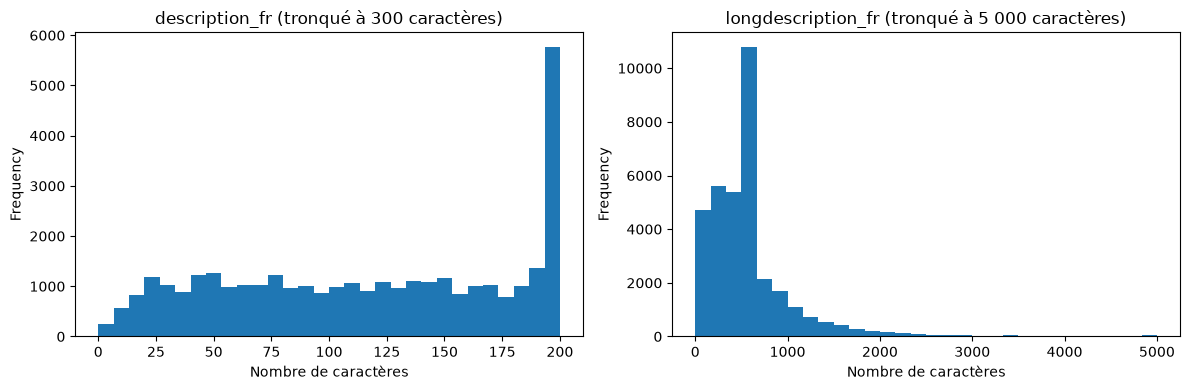

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lengths["description_fr"].clip(upper=300).plot.hist(bins=30, ax=axes[0], title="description_fr (tronqué à 300 caractères)")
lengths["longdescription_fr"].clip(upper=5000).plot.hist(bins=30, ax=axes[1], title="longdescription_fr (tronqué à 5 000 caractères)")
for ax in axes:
    ax.set_xlabel("Nombre de caractères")
plt.tight_layout()
plt.show()

In [20]:
poor_text = (lengths["description_fr"] < 30) & (lengths["longdescription_fr"] < 30)
print(f"Événements avec très peu de texte (description et description longue < 30 caractères) : {poor_text.sum()}")
df.loc[poor_text, ["title_fr", "description_fr", "longdescription_fr"]].head(10)

Événements avec très peu de texte (description et description longue < 30 caractères) : 406


,title_fr,description_fr,longdescription_fr
73,Réunion d'information,Réunion d'information,<p>Réunion d'information</p>
119,Célébrons les Producteurs de chez Nous au U EXPRESS LE BARP,.,NaN
120,Célébrons les Producteurs de chez Nous au UTILE ST-GEORGES-DE-DIDONNE Carn,.,NaN
121,Célébrons les Producteurs de chez Nous au U EXPRESS LEOGNAN,.,NaN
170,Ciné-rencontre,Ciné-rencontre,<p>OUTDOOR</p>
358,Quiz musical,avec Ricochet sonore,NaN
461,Concours de gâteaux,“Un Goûter Presque Parfait”,NaN
466,Dictée avec Mme Dourthe Rose-Marie,merci d’apporter un stylo,NaN
468,Activité cognitive :,dictée de l’été,NaN
619,Découverte des bols tibétains avec Mr Mezzo,(senior bénévole),NaN


In [21]:
total_characters = lengths.sum(axis=1).sum()
print(f"Volume total de texte : {total_characters / 1e6:.1f} millions de caractères")
CHARS_PER_TOKEN = 2.7   # mesuré avec le tokenizer de Mistral sur ces textes en français (et non 4, valeur de l'anglais)
print(f"Ordre de grandeur en tokens (≈ {CHARS_PER_TOKEN} caractères par token en français) : {total_characters / CHARS_PER_TOKEN / 1e6:.1f} millions")

Volume total de texte : 25.5 millions de caractères
Ordre de grandeur en tokens (≈ 2.7 caractères par token en français) : 9.4 millions


## 6. Les thèmes

Open Agenda contient **tous** les événements publics, pas seulement culturels. Quels sont les thèmes les plus fréquents, et quelle part d'événements semble non culturelle ?

In [22]:
has_keywords = df["keywords_fr"].map(lambda k: isinstance(k, list) and len(k) > 0)
print(f"Événements avec au moins un mot-clé : {has_keywords.mean():.1%}")

keywords = df["keywords_fr"].dropna().explode().dropna().astype(str).str.strip().str.lower()
keywords.value_counts().head(30)

Événements avec au moins un mot-clé : 72.8%


keywords_fr
s'informer                     5675
recrutement                    5105
#tousmobilisés                 4427
découverte secteur / métier    4203
découverte formation           2977
marché du travail              2778
création d'entreprise          2168
se préparer                    1798
aides à l'emploi               1667
bordeaux                       1580
insertion                      1533
1 jeune  1 solution            1497
spectacle                       641
culture                         588
la semaine de l'industrie       586
théâtre                         583
atelier                         557
les outils du numérique         526
musique                         517
concert                         483
recrutement sans cv             440
rencontre                       410
1 jour                          402
1 formation                     402
interim                         394
danse                           389
coaching                        386
tour de l emploi

In [23]:
# Agendas d'origine les plus représentés
df["originagenda_title"].value_counts().head(20)

originagenda_title
Mes événements France Travail                                   13592
Journées européennes du patrimoine 2026 - Nouvelle-Aquitaine     3111
Bibliothèques de Bordeaux                                        1319
SCARE - Syndicat des Cinémas d'Art, de Répertoire et d'Essai      710
Opéra National de Bordeaux                                        629
Rendez-vous aux jardins 2026 : Nouvelle-Aquitaine                 434
Semaine de l'industrie 2025                                       425
Semaine de l'industrie 2026                                       380
Challenges Geovelo                                                373
Cap Métiers                                                       316
Accueil agenda spectacle vivant - DRAC : Nouvelle-Aquitaine       307
Ville de Saint-Médard-en-Jalles                                   288
Musée d'Aquitaine                                                 268
Nuit européenne des musées 2026 : Nouvelle-Aquitaine              265
S

In [24]:
# Indices de contenus non culturels : liste indicative, pour mesurer l'ampleur ; aucun filtre par mots-clés
# n'est retenu (règle 5 : faux positifs)
NON_CULTURAL_HINTS = r"emploi|recrut|job dating|intérim|bénévol|permanence|réunion publique|formation professionnelle|atelier linguistique|insertion"
title_and_description = df["title_fr"].fillna("") + " " + df["description_fr"].fillna("")
hints = title_and_description.str.contains(NON_CULTURAL_HINTS, case=False, regex=True)
print(f"Événements contenant un indice non culturel : {hints.sum()} ({hints.mean():.1%})")
df.loc[hints, ["title_fr", "originagenda_title"]].sample(min(15, int(hints.sum())), random_state=42)

Événements contenant un indice non culturel : 7574 (21.9%)


,title_fr,originagenda_title
23109,Atelier Bénévolat,Mes événements France Travail
12343,Permanence IAE rencontre avec la structure VIVRACTIF,Mes événements France Travail
29012,PERMANENCE ECF- Découvrez les formations de financées par la Région Nouvelle...,Mes événements France Travail
25850,ATELIER SUR LES SOLUTIONS DE MOBILITE AVEC MOBIVIENNE,Mes événements France Travail
33029,Café des possibilités professionnelles Moncontour,Mes événements France Travail
31994,Les mercredis de l'intérim : Rencontre avec AQUILA RH,Mes événements France Travail
33486,Journée de recrutement,Semaine des métiers du tourisme 2026
7230,"Cariste, mécanicien, monteur : des métiers en tension à portée de main !",Mes événements France Travail
10454,Recrutements et Clauses Sociales : Ouvrez la porte à de nouvelles opportunit...,Mes événements France Travail
5907,Le GEIQ BTP recrute !,Mes événements France Travail


## 7. Le temps

Répartition entre événements passés et à venir, nombre d'événements par mois (en heure de Paris), séances multiples et décalages horaires.

In [25]:
is_upcoming = lastdate_end >= REFERENCE_DATE
print(f"Terminés (dans l'année écoulée) : {(~is_upcoming).sum()}")
print(f"À venir ou en cours             : {is_upcoming.sum()}")

Terminés (dans l'année écoulée) : 29298
À venir ou en cours             : 5219


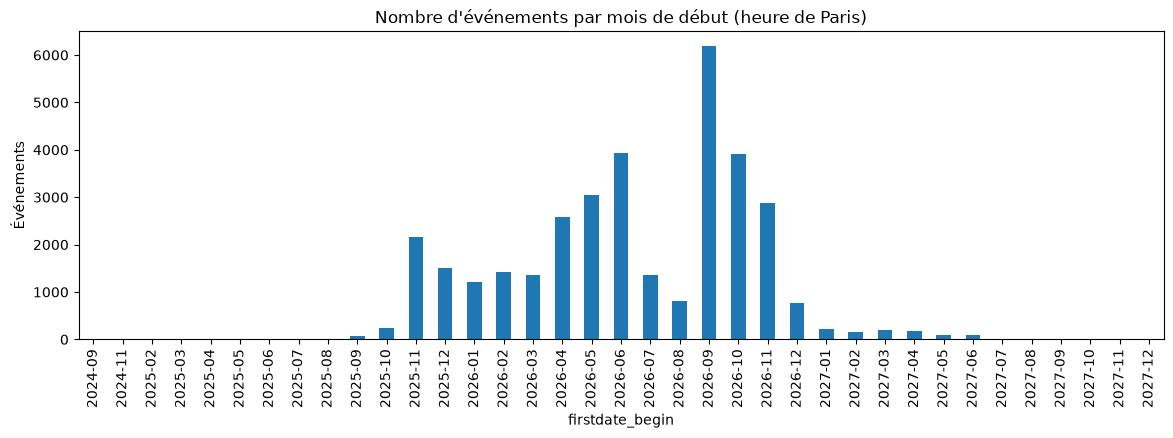

Débuts hors de la fenêtre affichée (avant 2024, après 2027 ou illisibles) : 41


In [26]:
start_month = firstdate_begin.dt.tz_convert("Europe/Paris").dt.strftime("%Y-%m")
in_window = start_month.between("2024-01", "2027-12")

ax = start_month[in_window].value_counts().sort_index().plot.bar(figsize=(14, 4))
ax.set_title("Nombre d'événements par mois de début (heure de Paris)")
ax.set_ylabel("Événements")
plt.show()
print(f"Débuts hors de la fenêtre affichée (avant 2024, après 2027 ou illisibles) : {(~in_window).sum()}")

In [27]:
def parse_timings(value) -> list[dict]:
    """Les séances arrivent sous forme de texte JSON (ou de liste) : on les convertit en liste."""
    if isinstance(value, str):
        return json.loads(value)
    return value if isinstance(value, list) else []


sessions = df["timings"].map(parse_timings)
print("Nombre de séances par événement :")
print(sessions.map(len).describe().round(1))

offsets = sessions.explode().dropna().map(lambda session: session["begin"][-6:])
print("\nDécalages horaires des séances :")
print(offsets.value_counts())

Nombre de séances par événement :
count    34517.0
mean         2.9
std         15.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max        783.0
Name: timings, dtype: float64

Décalages horaires des séances :
timings
+02:00    66161
+01:00    33285
Name: count, dtype: int64


## 8. Synthèse : constats et règles de nettoyage

Chaque règle découle d'un constat chiffré dans les sections précédentes. Elle est codée dans `rag/preprocess.py` et vérifiée par des tests (`tests/test_preprocess.py`, `tests/test_processed_data.py`). **Les règles sont du code, rejoué à chaque reconstruction de l'index** (`build_index` ou `/rebuild`) : elles doivent donc être **génériques**, valables aussi pour des données qu'on n'a pas encore vues. Le chatbot n'interroge pas Open Agenda en direct : il lit l'index construit lors de la dernière reconstruction.

| # | Constat (photo du 29/10/2026) | Règle de nettoyage | Effet sur la photo |
|---|---|---|---|
| 1 | 1 213 doublons de contenu sur les données brutes (même événement publié plusieurs fois, `uid` différents) | Clé normalisée (titre et lieu en minuscules, espaces réduits, + date de début) ; on garde le `updatedat` le plus récent ; appliquée **en dernier**, pour garder une copie conforme aux autres règles | −517 (après les autres filtres) |
| 2 | 41 hébergements datés du 01/01/2032 (date bouche-trou) | Exclure les événements qui commencent plus de 2 ans après la date de référence | −41 |
| 3 | 77 annulés, 240 complets, 15 re-programmés, 1 reporté | Exclure les annulés ; garder les autres avec un statut lisible | −77 |
| 4 | 17 départements incohérents avec le code postal (« gironde », Thiviers étiqueté « Charente »…) | Recalculer le département à partir du code postal (Nouvelle-Aquitaine) | 17 corrigés |
| 5 | 39 % d'événements « Mes événements France Travail » ; mots-clés dominés par l'emploi | Exclure une liste relue de 6 agendas emploi et formation (`config.py`) ; pas de filtre par mots-clés (faux positifs : balades guidées, métiers d'art) | −15 107 |
| 6 | Loisirs non strictement culturels (vélo, randonnée, agriculture) | Garder : ce sont des sorties grand public | 0 |
| 7 | Données qui évoluent en continu | `/rebuild` à la demande (POC) ; reconstruction nocturne incrémentale en perspective | — |
| 8 | 94,6 % des descriptions longues contiennent du HTML | Extraire le texte avec `html.parser` (bibliothèque standard) | — |
| 9 | Statut, mode, séances, inscription stockés comme du texte JSON | Décoder : `status_id`, `status_label`, `attendance_label`, listes | — |
| 10 | Dates en UTC | Convertir en heure de Paris (Europe/Paris) | — |
| 11 | 406 événements presque sans texte (« . ») | Garder ; vider les descriptions qui ne contiennent que de la ponctuation | 0 |
| 12 | Sortie du nettoyage | `data/processed/events_<zone>_<date>.json.gz`, non versionné (régénérable) | — |
| 13 | 4 événements sans aucun texte en français (découverts par un test de données ; le taux de 99,99 % s'affichait « 100,0 % ») | Exclure les événements sans titre | −4 |

*Les effets se recoupent en partie : le total retiré est mesuré lors de l'exécution du nettoyage.*

**Résultat sur la photo de référence : 34 517 → 18 771 événements** (−15 107 agendas exclus, −77 annulés, −41 dates aberrantes, −4 sans titre, −517 doublons ; 17 départements corrigés), d'après le rapport de `python -m scripts.preprocess_events`.

**Constats sans règle** :
- 217 codes postaux absents (197) ou d'une autre région (20), pour des événements dont le département déclaré est en Nouvelle-Aquitaine : le département déclaré est gardé quand le code postal ne permet pas de le déduire (règle 4) ;
- 17 coordonnées GPS hors du rectangle de la région : l'assistant n'utilise pas les coordonnées (le lieu est filtré sur la ville et le département), aucune règle n'est nécessaire.